# Lab 10: Wikipedia's APIs

*INFO 4617/5617 · Week 10 · Chapter 10, [Introduction to APIs: Wikipedia](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-10-wikipedia.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it.

By the end you'll have asked two of Wikipedia's APIs for one article's whole public record: its basic facts, every edit since 2003, its daily readers, who those readers are, and what the article connects to. Then you'll do the same with a client library in three lines.

**The article:** [University of Colorado Boulder](https://en.wikipedia.org/wiki/University_of_Colorado_Boulder), the chapter's case. Once a step works, try it on an article you care about.

**Before class:** open this notebook in the `webdata` environment (chapter 1), and have your email address ready for the User-Agent.

> **Instructor key.** Every cell is filled in and was run against the live APIs on 2026-10-20, with every request ending 2026-09-30, so most outputs will match a rerun. The article's current length (Step 2) and anything you ask for past that date will not.

## Step 0 — Set up (5 minutes)

Import `requests`, `pandas`, and `matplotlib`. Then define the User-Agent every request will send. Wikimedia's [User-Agent policy](https://foundation.wikimedia.org/wiki/Policy:Wikimedia_Foundation_User-Agent_Policy) asks every client to say who it is and how to reach its operator, in this form: `<client name>/<version> (<contact information>) <library name>/<version>`. Keep the first two parts in `CLIENT`, because Step 9's library adds its own name, and add `requests` and its version for `HEADERS`. A client the [rate limits](https://www.mediawiki.org/wiki/Wikimedia_APIs/Rate_limits) can identify only by its network address gets 10 requests a minute, shared with everyone on that network, which is everyone in this room. One with a User-Agent like this gets 200, and if it still gets a 429, the response's `Retry-After` header says how many seconds to wait.

In [1]:
# Import requests, pandas (as pd), and matplotlib.pyplot (as plt)
# Define CLIENT as "WebDataScience/1.0 (your-email@colorado.edu)", with your email
# Define HEADERS: a dict whose "User-Agent" is CLIENT, a space, then "python-requests/" and requests.__version__
# Define API, the Action API's address, and ARTICLE, the article's title
import requests
import pandas as pd
import matplotlib.pyplot as plt

CLIENT = "WebDataScience/1.0 (your-email@colorado.edu)"
HEADERS = {"User-Agent": f"{CLIENT} python-requests/{requests.__version__}"}
print(HEADERS)
API = "https://en.wikipedia.org/w/api.php"
ARTICLE = "University of Colorado Boulder"

{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu) python-requests/2.34.2'}


<details>
<summary>💬 Discuss</summary>

- In week 2 we wrote a User-Agent too. What does this one add, and who reads it?
- Why does the rate limit treat everyone in this room as one client, unless each of us says who we are?
- Wikipedia's `robots.txt` (week 2) disallows `/w/`, yet the API lives at `/w/api.php`. Why isn't that a contradiction?

</details>

## Step 1 — One request (5 minutes)

Every request to the MediaWiki [Action API](https://www.mediawiki.org/wiki/API:Action_API) has four parts: the base URL, an `action` (what to do), parameters that narrow it, and a `format`. Build the parameters as a dictionary, and `requests` turns them into the URL. Ask for `prop=info`, the article's basic facts, and look at the status code before anything else.

In [2]:
# Build params: action=query, titles=ARTICLE, prop=info, format=json
# Send the request with HEADERS, print the status code, stop if it isn't 200, then print the JSON
params = {"action": "query", "titles": ARTICLE, "prop": "info", "format": "json"}
response = requests.get(API, params=params, headers=HEADERS, timeout=30)
print(response.status_code)
response.raise_for_status()
data = response.json()
print(data)

200
{'batchcomplete': '', 'query': {'pages': {'289672': {'pageid': 289672, 'ns': 0, 'title': 'University of Colorado Boulder', 'contentmodel': 'wikitext', 'pagelanguage': 'en', 'pagelanguagehtmlcode': 'en', 'pagelanguagedir': 'ltr', 'touched': '2026-10-18T22:35:28Z', 'lastrevid': 1380813690, 'length': 95112}}}}


<details>
<summary>💬 Discuss</summary>

- Our first request in week 1 fetched this same article as HTML. What's different about what came back this time?
- Print `response.url`. Where are the four parts of the request in it (week 5's URL anatomy), and which one would you change to ask about another article?
- What would a 403 or a 429 here tell you, and which of them is about you?

</details>

## Step 2 — Read the JSON one level at a time (5 minutes)

The answer is nested: `data["query"]["pages"]`, then a key that is the page's ID. We don't know the ID in advance, so take the first (and only) value. Print the title, the page ID, and the article's length in bytes.

In [3]:
# Go down one level at a time: data -> "query" -> "pages" -> the one page inside
# Print its title, pageid, and length
pages = data["query"]["pages"]
page = list(pages.values())[0]
print(page["title"], page["pageid"], f"{page['length']:,} bytes")

University of Colorado Boulder 289672 95,112 bytes


<details>
<summary>💬 Discuss</summary>

- Why is the page ID a key rather than a value? What does that let the API do when you ask about several titles at once?
- In week 6 we scraped Wikipedia infoboxes with BeautifulSoup. Which approach breaks first when Wikipedia redesigns its pages?
- The length is in bytes, not words. What would you need to know before comparing two articles by it?

</details>

## Step 3 — Every edit, one batch at a time (15 minutes)

`prop=revisions` returns an article's edits, newest first, at most 500 per request. When there are more, the response carries a `"continue"` key: add its contents to your parameters and ask again, until it's gone. Forgetting this loop is the most common API bug there is, because the first batch looks like a complete answer.

This step sends many requests, so first write `get(url, params)`, the one way every request from here on goes out. It always sends `HEADERS`, and when the answer is a 429 it waits as many seconds as `Retry-After` says and asks again, up to three times, as the rate-limit page asks.

Then write `get_revisions(title)`. Use `rvstart` to fix the newest edit you'll accept, `2026-09-30T23:59:59Z`, so that running it next week gives today's answer. Call `raise_for_status()` before `.json()`: if the rate limit still answers, you'll see why instead of a confusing JSON error.

In [4]:
# Import time. Define get(url, params=None):
#   up to four tries: request url with params and HEADERS (timeout=30); return the response
#   unless it is a 429, in which case time.sleep() for int(response.headers["Retry-After"]) seconds
# Define get_revisions(title):
#   params: action=query, titles, prop=revisions, rvprop=ids|timestamp|user|size|comment,
#           rvlimit=max, rvstart="2026-09-30T23:59:59Z", format=json
#   loop: get(API, params), raise_for_status, keep this batch's revisions,
#         and if "continue" is in the response, add it to params; otherwise stop
#   return the revisions as a DataFrame
# Call it for ARTICLE and print how many revisions came back
import time

def get(url, params=None):
    for attempt in range(4):
        response = requests.get(url, params=params, headers=HEADERS, timeout=30)
        if response.status_code != 429 or attempt == 3:
            return response
        wait = int(response.headers.get("Retry-After", 5))
        print(f"429: waiting {wait} seconds")
        time.sleep(wait)

def get_revisions(title, until="2026-09-30T23:59:59Z"):
    params = {"action": "query", "titles": title, "prop": "revisions",
              "rvprop": "ids|timestamp|user|size|comment",
              "rvlimit": "max", "rvstart": until, "format": "json"}
    revisions = []
    while True:
        response = get(API, params)
        response.raise_for_status()
        data = response.json()
        page = list(data["query"]["pages"].values())[0]
        revisions.extend(page.get("revisions", []))
        if "continue" in data:
            params.update(data["continue"])
        else:
            break
    return pd.DataFrame(revisions)

revisions = get_revisions(ARTICLE)
print(f"{len(revisions):,} revisions")

429: waiting 52 seconds


429: waiting 1 seconds


2,988 revisions


<details>
<summary>💬 Discuss</summary>

- How many requests did `get_revisions()` send? Without the `continue` loop, how many revisions would we have, and would anything warn us?
- Why fix `rvstart` at a date in the past? What does that give someone who reruns your notebook next year?
- Week 7's Wayback captures and this history are both versions of a page over time. Which is the more complete record, and why?

</details>

## Step 4 — Chart the edits, and find the editors (5 minutes)

Turn `timestamp` into dates, count edits per month with `resample("ME")`, and plot them. Then use `value_counts()` on `user` to see who edits most, and what share of all edits the top ten made.

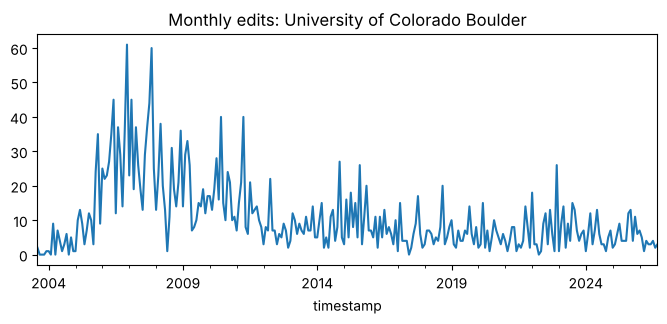

user
Kerowyn              92
MECU                 82
ElKevbo              78
Contributor321       49
Kvng                 40
Wordbuilder          37
Fleminra             27
Levineps             24
Corkythehornetfan    23
Rookkey              22
Name: count, dtype: int64
Top 10 share: 15.9%


In [5]:
# Convert timestamp to datetimes, count edits per month, and plot them
# Show the ten most active editors, and the share of all edits they made
revisions["timestamp"] = pd.to_datetime(revisions["timestamp"])
monthly = revisions.set_index("timestamp").resample("ME").size()

fig, ax = plt.subplots(figsize=(8, 3))
monthly.plot(ax=ax)
ax.set_title(f"Monthly edits: {ARTICLE}")
plt.show()

top = revisions["user"].value_counts().head(10)
print(top)
print(f"Top 10 share: {top.sum() / len(revisions):.1%}")

<details>
<summary>💬 Discuss</summary>

- Most edits came in the article's first few years. What does that suggest about how an article matures?
- The ten most active editors made about one edit in six. Is that concentrated? What would you compare it with?
- Usernames are public. Does that make it fine to publish a ranking of an article's editors?

</details>

## Step 5 — A second API for readers (5 minutes)

Pageviews come from a different API, Wikimedia's REST API, whose parameters are parts of the URL's path rather than a dictionary: project, access, **agent** (who is reading), article, granularity, start, and end. Define `get_pageviews()` in this cell, and use it in the next. Titles in the path use underscores, not spaces.

In [6]:
# Define get_pageviews(title, start, end, agent="user", granularity="daily"):
#   build the URL: https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article
#                  /en.wikipedia/all-access/{agent}/{article}/{granularity}/{start}/{end}
#   request it with get(), raise_for_status, make a DataFrame from ["items"]
#   turn "timestamp" (YYYYMMDDHH) into dates, and return the timestamp and views columns
def get_pageviews(title, start, end, agent="user", granularity="daily"):
    article = title.replace(" ", "_")
    url = ("https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article"
           f"/en.wikipedia/all-access/{agent}/{article}/{granularity}/{start}/{end}")
    response = get(url)
    response.raise_for_status()
    views = pd.DataFrame(response.json()["items"])
    views["timestamp"] = pd.to_datetime(views["timestamp"], format="%Y%m%d%H")
    return views[["timestamp", "views"]]

<details>
<summary>💬 Discuss</summary>

- The Action API takes its parameters in the query string; this one takes them in the path. How can you tell which kind of API you have?
- Why doesn't this function need a `continue` loop?
- In week 1 we asked this API for `all-agents`. What changes when we ask for `user`?

</details>

## Step 6 — Plot the readers, and find the biggest day (8 minutes)

Get daily views from January 1, 2021 to September 30, 2026, plot them, and find the peak with `idxmax()`. What happened that day? The API's days are UTC days, so an evening event in Colorado lands on the next one.

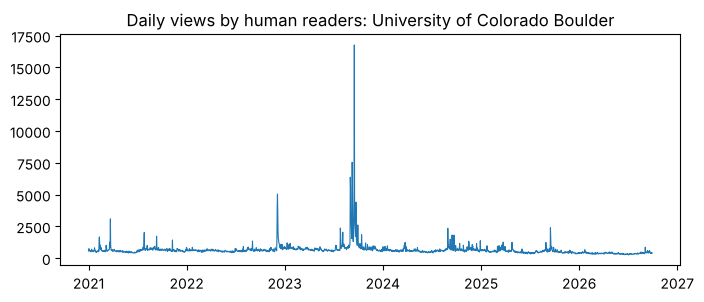

2023-09-17 16,767 views


In [7]:
# Get daily views for ARTICLE from 20210101 to 20260930, and plot them
# Find the day with the most views, and print its date and count
views = get_pageviews(ARTICLE, "20210101", "20260930")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(views["timestamp"], views["views"], linewidth=0.8)
ax.set_title(f"Daily views by human readers: {ARTICLE}")
plt.show()

peak = views.loc[views["views"].idxmax()]
print(peak["timestamp"].date(), f"{peak['views']:,} views")

<details>
<summary>💬 Discuss</summary>

- The API's days are UTC days. What mistake could you make reporting the peak as a Colorado date?
- What happened around the peak? How would you check it with data, such as the revisions around that date, rather than from memory?
- A spike measures attention, not approval. Which claims can it support, and which can't it?

</details>

## Step 7 — Who is reading? (7 minutes)

A pageview is not a person. Wikimedia splits its counts by agent: `user` (people), `spider` (crawlers that say what they are), and `automated` (bots that don't). Call `get_pageviews()` once for each, with monthly granularity, for 2024 to September 2026, and plot the three together. When Wikimedia improved its bot detection in 2025, it moved past traffic from one agent to another.

429: waiting 1 seconds


429: waiting 53 seconds


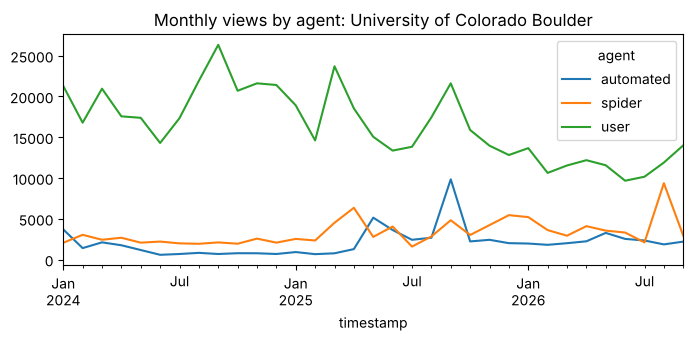

In [8]:
# For each agent in user, spider, automated: get monthly views from 20240101 to 20260930
# Put them in one DataFrame, one column per agent (pivot), and plot it
frames = []
for agent in ["user", "spider", "automated"]:
    monthly_views = get_pageviews(ARTICLE, "20240101", "20260930", agent=agent, granularity="monthly")
    monthly_views["agent"] = agent
    frames.append(monthly_views)
by_agent = pd.concat(frames).pivot(index="timestamp", columns="agent", values="views")

by_agent.plot(figsize=(8, 3), title=f"Monthly views by agent: {ARTICLE}")
plt.show()

<details>
<summary>💬 Discuss</summary>

- What share of the views are people? How would a study's conclusions change if it had used `all-agents`?
- Wikimedia moved past traffic from one agent to another when its bot detection improved. What does that mean for anyone who downloaded counts before then?
- Our Selenium visits in week 8 came from a real browser. Which agent should they count as, and which do you think they did?

</details>

## Step 8 — One function for everything else (10 minutes)

Links, categories, templates, languages, and what links here are all `action=query`, with a different `prop` or `list`, and they all paginate the same way. So write the loop once: `query_all(params)` follows `"continue"` and returns every batch. Then count the article's categories, its language editions, and the articles that link to it.

Look at the first few categories: some are **hidden** maintenance categories that readers never see. Add `clshow="!hidden"` to leave them out.

In [9]:
# Define query_all(params): add action=query and format=json, then loop like Step 3,
#   collecting each response's "query" part; return the list of batches
# Use it to count: categories (prop=categories, cllimit=max), with and without clshow="!hidden";
#   language editions (prop=langlinks, lllimit=max);
#   articles linking here (list=backlinks, bltitle, bllimit=max, blnamespace=0)
def query_all(params):
    params = {"action": "query", "format": "json", **params}
    batches = []
    while True:
        response = get(API, params)
        response.raise_for_status()
        data = response.json()
        batches.append(data["query"])
        if "continue" in data:
            params.update(data["continue"])
        else:
            break
    return batches

def page_items(title, prop, extra):
    items = []
    for batch in query_all({"titles": title, "prop": prop, **extra}):
        for page in batch["pages"].values():
            items.extend(page.get(prop, []))
    return items

categories = page_items(ARTICLE, "categories", {"cllimit": "max"})
visible = page_items(ARTICLE, "categories", {"cllimit": "max", "clshow": "!hidden"})
languages = page_items(ARTICLE, "langlinks", {"lllimit": "max"})
backlinks = [b for batch in query_all({"list": "backlinks", "bltitle": ARTICLE,
                                       "bllimit": "max", "blnamespace": 0})
             for b in batch["backlinks"]]
print(f"{len(categories)} categories, {len(visible)} visible to readers")
print(f"{len(languages)} other language editions")
print(f"{len(backlinks):,} articles link here")

429: waiting 57 seconds


429: waiting 1 seconds


40 categories, 9 visible to readers
38 other language editions
3,298 articles link here


<details>
<summary>💬 Discuss</summary>

- Why does one loop work for categories, language links, and backlinks alike?
- Hidden categories are maintenance labels that readers never see. Should a study of how Wikipedia classifies a topic include them?
- Dozens of other editions have an article on this topic. What could you learn by comparing them, as week 6 did with French infoboxes?

</details>

## Step 9 — The same with a client library (5 minutes)

[mwclient](https://mwclient.readthedocs.io/) does the continuation for you. If you haven't installed it, run `%conda install -y -c conda-forge mwclient` in a new cell first; conda-forge has version 0.10.1. Ask it for the same article's categories, language editions, and revisions. In mwclient 0.10, `limit` is how many results to ask for in each request; version 0.11 calls it `api_chunk_size`.

Two things stay raw. mwclient speaks only the Action API, so pageviews still need Step 5. And it doesn't wait on a 429: it stops with an error. So make the `Site` with `do_init=False`, which sends nothing yet, and give its session (`site.connection`) a retry rule from `urllib3`, the library under `requests`: on a 429, wait as long as `Retry-After` says and try again, up to five times. Then `site.site_init()` sends the first request.

In [10]:
# Import mwclient and print its version
# Make a Site for en.wikipedia.org with clients_useragent=CLIENT (mwclient adds its own name and version)
#   and do_init=False; mount HTTPAdapter(max_retries=Retry(total=5, status_forcelist=[429]))
#   on site.connection for "https://", then call site.site_init()
# Get the page, then count its categories, its language editions,
#   and its revisions up to 2026-09-30T23:59:59Z, 500 per request (limit=500)
import mwclient
print(mwclient.__version__)

from requests.adapters import HTTPAdapter
from urllib3.util import Retry

site = mwclient.Site("en.wikipedia.org", clients_useragent=CLIENT, do_init=False)
site.connection.mount("https://", HTTPAdapter(max_retries=Retry(total=5, status_forcelist=[429])))
site.site_init()
print(site.connection.headers["User-Agent"])
page = site.pages[ARTICLE]
print(len(list(page.categories())), "categories")
print(len(list(page.langlinks())), "language editions")
print(len(list(page.revisions(start="2026-09-30T23:59:59Z", limit=500))), "revisions")

0.10.1


WebDataScience/1.0 (your-email@colorado.edu) mwclient/0.10.1 (https://github.com/mwclient/mwclient)


40 categories
38 language editions


2988 revisions


<details>
<summary>💬 Discuss</summary>

- What did mwclient do for you that you wrote by hand in Steps 3 and 8? What didn't it do?
- When would you choose raw requests over a client library, for a project or for learning?
- Week 3 was about APIs that closed. Wikipedia's has stayed open. What keeps it open, and what would your project lose if it closed?

</details>

## Step 10 — What did we learn? (5 minutes)

In a few sentences, as comments or in a Markdown cell:

- Did the revision count from Step 3 match mwclient's in Step 9? What would it mean if it didn't?
- Does the biggest day in Step 6 line up with a burst of edits in Step 4?
- In Step 7, how much of the article's traffic is people? What would that mean for a study that used `all-agents`?
- Run Steps 1–8 again for an article you care about. What's different?

In [11]:
# Your answers here, as comments
# Steps 3 and 9 both return 2,988 revisions up to 2026-09-30: the loop and the library agree.
# The biggest day, 2023-09-17, falls in the busiest month for views since 2021 (97,904 human views)
#   but not for edits: September 2023 had 7, December 2022 had 26 (Step 4).
#   Readers come for news; editors don't always follow.
# Human readers are most of the traffic, but bots and crawlers are thousands of views a month;
#   all-agents would overstate human attention, and by different amounts from month to month.